Computing recurrence intervals with IMERG time series at Hunt, Texas\
July 2025 Flood Event

Extreme value analysis (EVA) method: Peaks Over Threshold (POT)

Jacob R. Schaperow - jacob.r.schaperow@nasa.gov\
Andrew M. Fisher - andrew.m.fisher@nasa.gov\
Ariana L. McDermott - ariana.m.louise@nasa.gov

In [1]:
# Import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pyextremes import EVA
import xarray as xr

1970-01-01 00:00:00.000000000    0.555
1970-01-01 00:00:00.000000001    1.940
1970-01-01 00:00:00.000000002    0.815
1970-01-01 00:00:00.000000003    3.405
1970-01-01 00:00:00.000000004    0.105
Name: precip_mm, dtype: float32
3555
<class 'pandas.Series'>
date-time
1970-01-01 00:00:00.000000065    135.234985
Name: precip_mm, dtype: float64


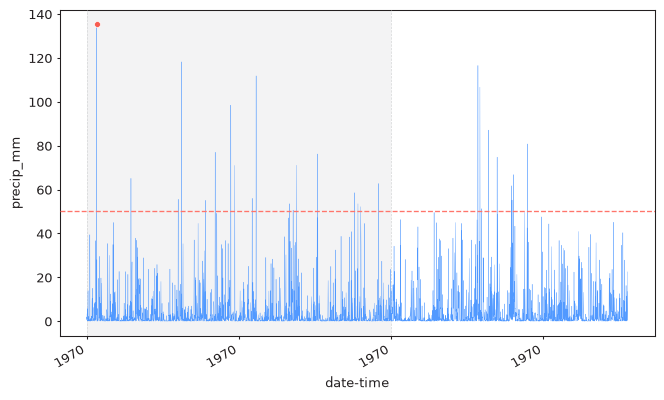

1970-01-01 00:00:00.000000000    2.800
1970-01-01 00:00:00.000000001    4.115
1970-01-01 00:00:00.000000002    0.980
1970-01-01 00:00:00.000000003    0.120
1970-01-01 00:00:00.000000004    0.525
Name: precip_mm, dtype: float32
3377
<class 'pandas.Series'>
date-time
1970-01-01 00:00:00.000002405    131.610001
Name: precip_mm, dtype: float64


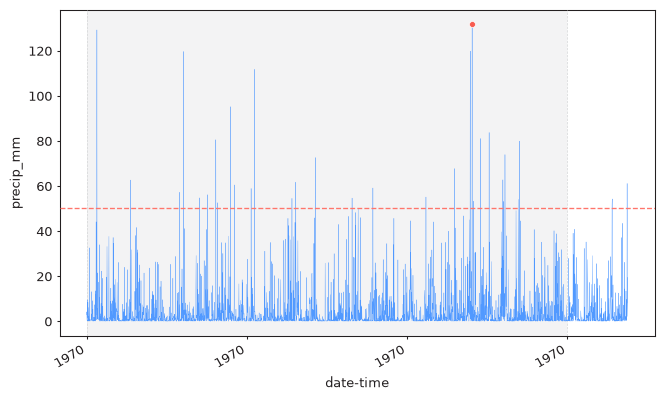

1970-01-01 00:00:00.000000000    1.150
1970-01-01 00:00:00.000000001    5.915
1970-01-01 00:00:00.000000002    0.830
1970-01-01 00:00:00.000000003    0.075
1970-01-01 00:00:00.000000004    0.090
Name: precip_mm, dtype: float32
3193
<class 'pandas.Series'>
date-time
1970-01-01 00:00:00.000002256    148.734985
Name: precip_mm, dtype: float64


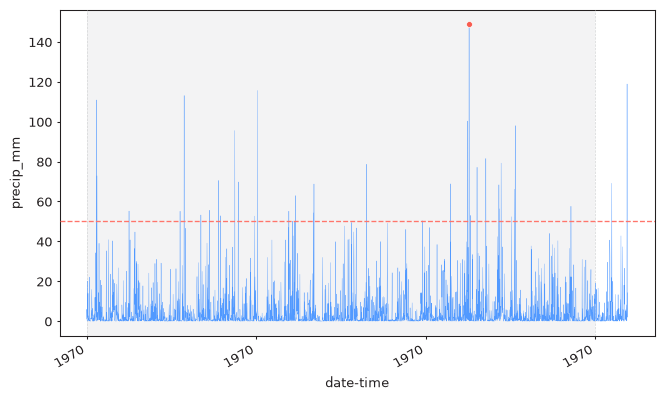

1970-01-01 00:00:00.000000000     0.270000
1970-01-01 00:00:00.000000001    22.305002
1970-01-01 00:00:00.000000002     0.805000
1970-01-01 00:00:00.000000003     0.025000
1970-01-01 00:00:00.000000004     0.050000
Name: precip_mm, dtype: float32
3086
<class 'pandas.Series'>
date-time
1970-01-01 00:00:00.000002142    143.174988
Name: precip_mm, dtype: float64


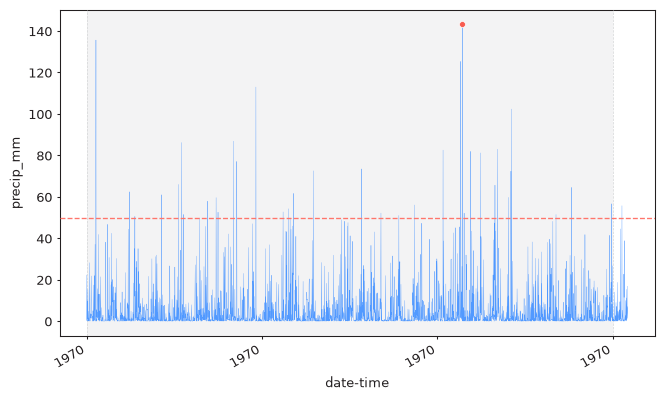

1970-01-01 00:00:00.000000000    23.994997
1970-01-01 00:00:00.000000001     0.710000
1970-01-01 00:00:00.000000002     0.140000
1970-01-01 00:00:00.000000003     0.280000
1970-01-01 00:00:00.000000004    10.544999
Name: precip_mm, dtype: float32
3036
<class 'pandas.Series'>
date-time
1970-01-01 00:00:00.000000050    132.929993
Name: precip_mm, dtype: float64


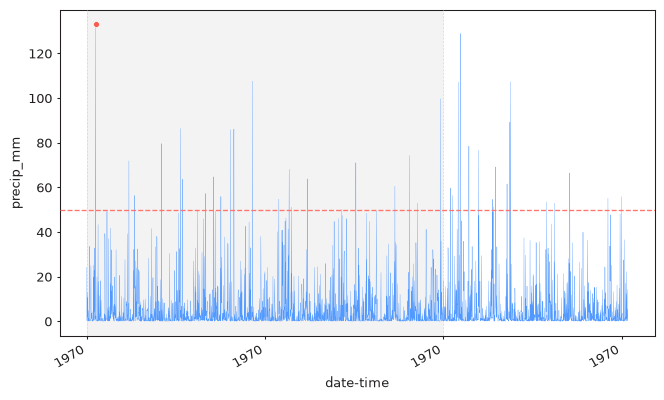

In [6]:
# Import time series data (edit to take a netcdf file)

#df = pd.read_csv('./Data/hunt_texas_IMERG_daily.txt')
#df.columns = ['date','precip_mm']
#df = ds.to_dataframe()

#val = ds.isel(lat=0, lon=5, time=0)

#read data in netcdf format with xarray and convert to a dataframe
# ds = xr.open_dataset(r"C:\Users\alouise\Documents\AGU2026\Testing\InputData\subset_kerchunk.nc", engine="netcdf4")
ds = xr.open_dataset("/Users/jschaper/Documents/Codes/gesdisc-tutorials/conference-presentations/agu-2026/IMERG_subsets/subset_kerchunk.nc", engine="netcdf4")

#print(ds.head())
#print(ds)

for i in range(0, 1): # range(1, len(ds.lat)) <-- this note might work better if you want to loop through all latitudes
    for j in range(0, 5): # in range(1, len(ds.lon) <-- this note might work better if you want to loop through all longitudes

        df = ds.isel(lat=i, lon=j)['precipitation'].to_dataframe().reset_index()[['time', 'lat', 'lon', 'precipitation']]
        df.columns = ['date','lat','lon','precip_mm']
        df_series = df.set_index(['date', 'lat', 'lon'])['precip_mm']
        df_noz = df_series[df_series > 0].reset_index(drop=True) #<-- I don't know if reset index is needed here
        df_noz.index = pd.to_datetime(df_noz.index)

        print(df_noz.head())
        print(len(df_noz)) #<-- this is a test for this loop to 'do something', i.e. - print the first 5 rows of the dataframe for each lat/lon combination
        print(type(df_noz))
        
        model = EVA(df_noz)
        model.get_extremes("POT", threshold=50, r='48hr')
        print(model.extremes.head())
        model.plot_extremes(show_clusters=True)

        plt.show()


 #CAN DO THIS AT THE END
        #add threshold and radius columns to the dataframe
        #new_columns = ['radius', 'threshold']
        #df = df.assign(**{col: np.nan for col in new_columns}) #populate the new columns with NaN values
        #print(df.head())


In [44]:
# Clean data by removing zeros

df_noz = ds_series[['precip_mm']] > 0

print(df_noz.head())
print(len(df_noz))
print(len(ds_series))

KeyError: "None of [Index(['precip_mm'], dtype='object', name='date')] are in the [index]"

In [ ]:
# Creating a model for the time series data using the Peaks Over Threshold (POT) method
model = EVA(df_noz)
model.get_extremes("POT", threshold=50, r='48hr')

print(model.extremes.head())

model.plot_extremes(show_clusters=True)

plt.show()

TypeError: invalid type in 'DataFrame' for the `data` argument, must be pandas.Series

In [66]:
# Estimating return periods - POT method

from pyextremes import get_extremes, get_return_periods

extremes = get_extremes(
    ts=df_noz,
    method="POT",
    threshold=45,
    r="24h",
)
return_periods = get_return_periods(
    ts=df_noz,
    extremes=extremes,
    extremes_method="POT",
    extremes_type="high",
    return_period_size="24h",
    plotting_position="weibull",
)
return_periods.sort_values("return period", ascending=False).head()

,precip_mm,exceedance probability,return period
date,,,
1998-10-06,107.755,0.015873,10295.419355
2025-07-04,104.625,0.031746,5147.709677
2024-07-23,99.590,0.047619,3431.806452
2002-07-04,98.555,0.063492,2573.854839
2001-11-15,94.000,0.079365,2059.083871


                           Univariate Extreme Value Analysis                            
                                      Source Data                                       
----------------------------------------------------------------------------------------
Data label:                     precip_mm      Size:                               3,221
Start:                       January 1998      End:                       September 2025
                                     Extreme Values                                     
----------------------------------------------------------------------------------------
Count:                                 62      Extraction method:                    POT
Type:                                high      Threshold:                             45
                                         Model                                          
----------------------------------------------------------------------------------------
Model:               

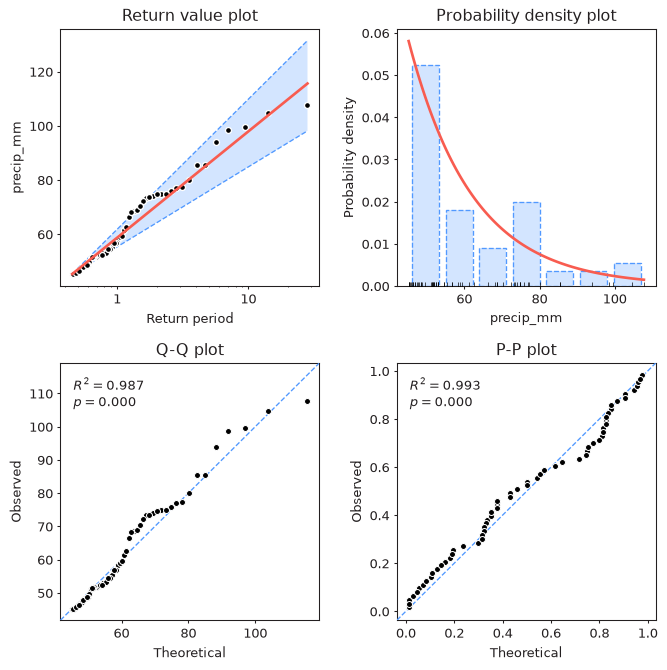

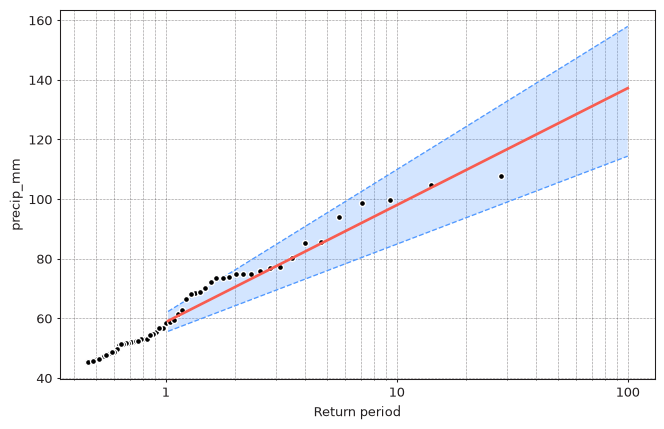

In [67]:
# Fit a model to the extreme values

model.fit_model() # default fitting method is MLE - Maximum Likelihood Estimate 
print(model)

model.plot_diagnostic(alpha=0.95)

model.plot_return_values(
    return_period = np.logspace(0.01,2,100),
    alpha = 0.95
)
plt.show()

In [75]:
# Estimate return values

summary = model.get_summary(
    return_period=[1, 2, 5, 10, 14, 25, 45, 50, 100],
    alpha=0.95,
    n_samples=100,
)
print(summary)

               return value    lower ci    upper ci
return period                                      
1.0               58.703698   55.311870   61.783236
2.0               70.514423   64.199299   76.248104
5.0               86.127352   75.947842   95.369619
10.0              97.938077   84.835272  109.834487
14.0             103.671320   89.149469  116.856122
25.0             113.551006   96.583815  128.956002
45.0             123.566464  104.120328  141.222165
50.0             125.361731  105.471245  143.420870
100.0            137.172456  114.358675  157.885738


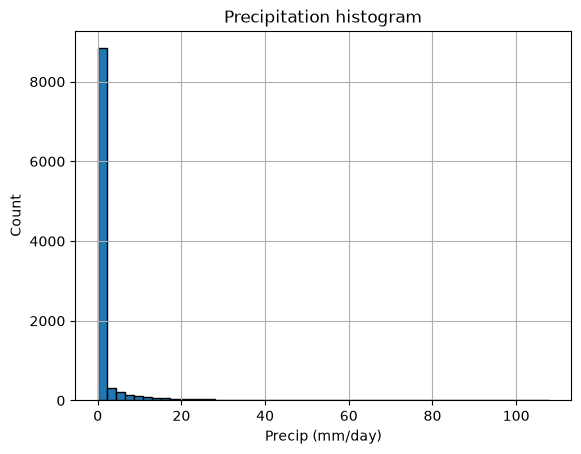

In [69]:
# Plot histogram (with zeros)

df['precip_mm'].hist(bins = 50, edgecolor='black')
plt.title('Precipitation histogram')
plt.xlabel('Precip (mm/day)')
plt.ylabel('Count')
plt.show()

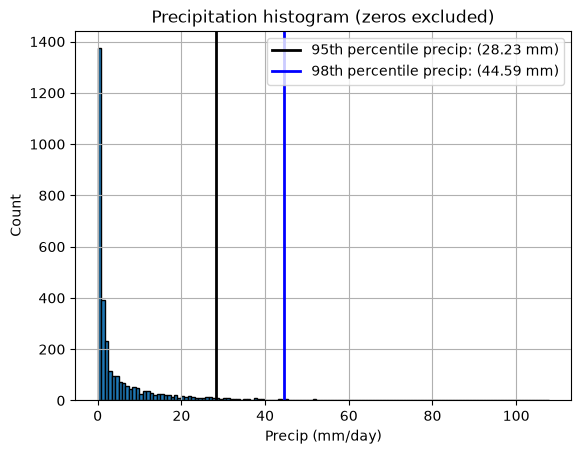

In [ ]:
# Plot histogram (without zeros)

df_noz = df[df['precip_mm']>0]
p95 = np.percentile(df_noz['precip_mm'], 95) # calculate 95% precipitation
p98 = np.percentile(df_noz['precip_mm'], 98) # calculate 98% precipitation

df_noz['precip_mm'].hist(bins = "fd", edgecolor='black')
plt.axvline(x = p95, 
    color = "black", 
    linewidth = 2, 
    label=f"95th percentile precip: ({p95:.2f} mm)"
)
plt.axvline(x = p98, 
    color = "blue", 
    linewidth = 2, 
    label=f"98th percentile precip: ({p98:.2f} mm)"
)

plt.title('Precipitation histogram (zeros excluded)')
plt.xlabel('Precip (mm/day)')
plt.ylabel('Count')
plt.legend()
plt.show()

161


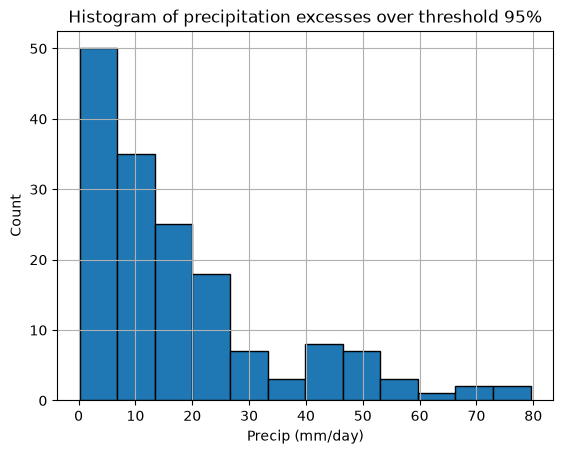

In [71]:
# Implement peak-over-threshold (POT) method

# Choosing threshold of p95 for peak-over-threshold method
threshold95 = p95 # this might be too low...

# Get precipitation data over the threshold value
df_peaks = df_noz[df_noz['precip_mm']>threshold95]
df_peaks.head()
print(len(df_peaks))

df_excesses = df_peaks['precip_mm'] - threshold95

# Plot histogram of extreme values
df_excesses.hist(bins = "fd", edgecolor = "black")
plt.title('Histogram of precipitation excesses over threshold 95%')
plt.xlabel('Precip (mm/day)')
plt.ylabel('Count')
plt.show()

# We should implement a check to remove consecutive peaks that are actually part of the same storm event
# For example, ensure there is at least one full day in between peaks
# This will help with independence, and satisfying the extreme value theorem, which requires i.i.d. random variables


65


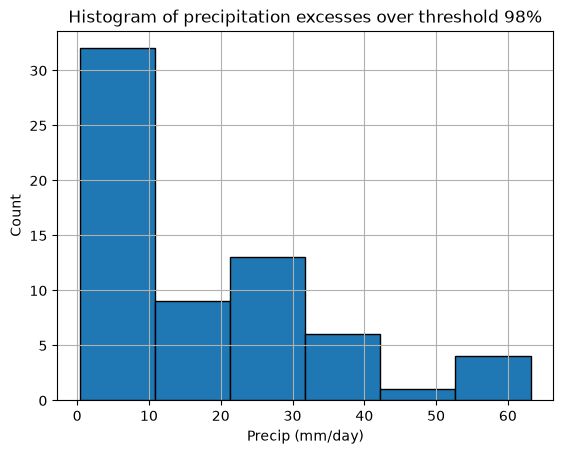

In [72]:
# Choosing threshold of p98 for peak-over-threshold method
threshold98 = p98

# Get precipitation data over the threshold value
df_peaks = df_noz[df_noz['precip_mm']>threshold98]
df_peaks.head()
print(len(df_peaks))

df_excesses = df_peaks['precip_mm'] - threshold98

# Plot histogram of extreme values
df_excesses.hist(bins = "fd", edgecolor = "black")
plt.title('Histogram of precipitation excesses over threshold 98%')
plt.xlabel('Precip (mm/day)')
plt.ylabel('Count')
plt.show()